<p style="text-align: center;"><span style="color: blue;"><strong><span style="font-size: x-large;">
    PROCESAMIENTO DE IMÁGENES DIGITALES</span></strong></span></p>

<p style="text-align: center;"><span style="color: blue;"><strong><span style="font-size: x-large;">PRÁCTICA 1: Ejercicios</span></strong></span></p>

In [1]:
import cv2 as cv 
import matplotlib.pyplot as plt 
import numpy as np

Matplotlib is building the font cache; this may take a moment.


### 📝 Ejercicio 1: 

- Carga una imagen en escala de grises y visualízala. ¿Qué tipo de dato es? 


In [2]:
im_gris = cv.imread('barco.jpg',0)
im_gris


array([[255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       ...,
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255]], shape=(850, 850), dtype=uint8)

In [4]:
type(im_gris)

numpy.ndarray

### 📝 Ejercicio 2: 

- Carga una imagen a color. ¿Qué tipo de dato es?
- Separa los tres canales de la imagen para visualizarlos por separado.

In [5]:
im_color = cv.imread('HSV.png')
im_color

array([[[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       ...,

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]]

In [5]:
b, g, r = cv.split(im_color)
cv.imshow('Canal Azul', b)
cv.imshow('Canal Verde', g)
cv.imshow('Canal Rojo', r)

cv.waitKey(0)
cv.destroyAllWindows()

Cada canal pasa a ser una matriz de un solo número por píxel. En estos mapas en escala de grises, el color no se representa con su tono, sino con la cantidad de luz. Un pixel claro significa que en esa zona hay mucho de ese color. Un pixer oscuro significa que en esa zona no hay nada de ese color.

### 📝 Ejercicio 3: 

- Convierte una imagen a color en escala de grises utilizando: (1). la fórmula: $Y = 0.299 * R + 0.587 * G + 0.114 * B$ y (2). la componente $I$ del modelo $HSI$. 
- ¿Cuál representa mejor la información de la imagen a color tal y como la vemos? ¿Por qué?

In [12]:
r_f = r.astype('float64')
g_f = g.astype('float64')
b_f = b.astype('float64')

Y = 0.299 * r_f + 0.587 * g_f + 0.114 * b_f
Y = Y.astype('uint8') 

I = (r_f + g_f + b_f) / 3.0
I = I.astype('uint8')

La primera fórmula representa mucho mejor la imagen tal y como la vemos los humanos. Es la fórmula de la Luminancia utilizada para calcular el brillo real de una foto a color.   

Nuestros ojos no perciben todos los colores con el mismo brillo. El ojo humano es mucho más sensible al color verde y muy poco sensible al azul. La fórmula de luminancia ($Y$) le da un $58.7\%$ de peso al verde, un $29.9\%$ al rojo y solo un $11.4\%$ al azul, imitando exactamente cómo funciona la retina humana.

La componente $I$ simplemente hace una media matemática exacta asignando el mismo peso ($33.3\%$) a cada color. Esto hace que las zonas azules se vean artificialmente muy brillantes en la imagen en grises, perdiendo el contraste real que percibe el ojo.

### 📝 Ejercicio 4: 

- Carga dos imágenes binarias sencillas y aplica las funciones de openCV: **bitwise_and**, **bitwise_or**, **bitwise_xor** y **bitwise_not**.

In [23]:
img1 = cv.imread('circulos_ruidos.png', 0)
img2 = cv.imread('pez.png', 0)

cv.imshow('Imagen circulos',img1)
cv.waitKey(0) 
cv.destroyAllWindows()


In [24]:

cv.imshow('Imagen pez',img2)
cv.waitKey(0) 
cv.destroyAllWindows()

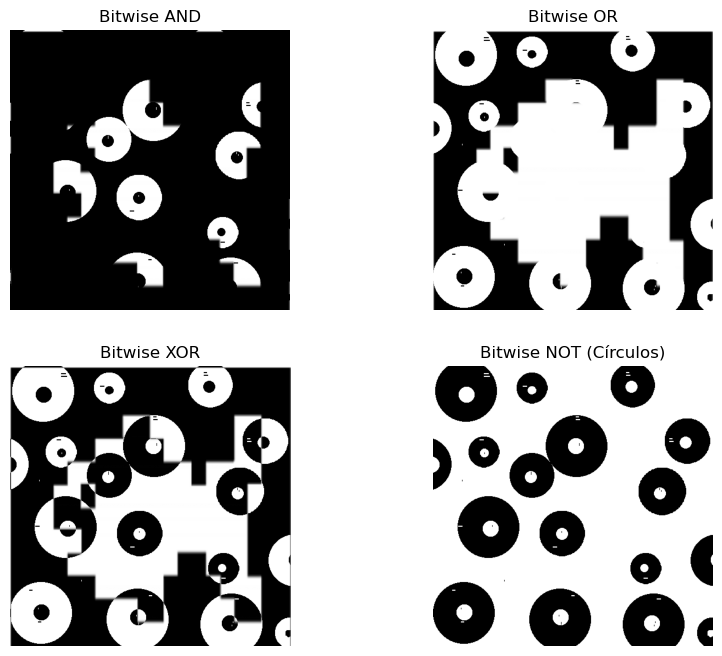

In [19]:
img2 = cv.resize(img2, (img1.shape[1], img1.shape[0]))

res_and = cv.bitwise_and(img1, img2)
res_or  = cv.bitwise_or(img1, img2)
res_xor = cv.bitwise_xor(img1, img2)
res_not = cv.bitwise_not(img1)


plt.figure(figsize=(10, 8))

plt.subplot(2, 2, 1)
plt.imshow(res_and, cmap='gray')
plt.title('Bitwise AND')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(res_or, cmap='gray')
plt.title('Bitwise OR')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(res_xor, cmap='gray')
plt.title('Bitwise XOR')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(res_not, cmap='gray')
plt.title('Bitwise NOT (Círculos)')
plt.axis('off')

plt.show()

### 📝 Ejercicio 5: 

- Carga dos imágenes sencillas en escalas de grises y aplica las funciones de openCV **add()** y **addWeighted()**.
- ¿Cuál es la diferencia con la suma directa de las imágenes?

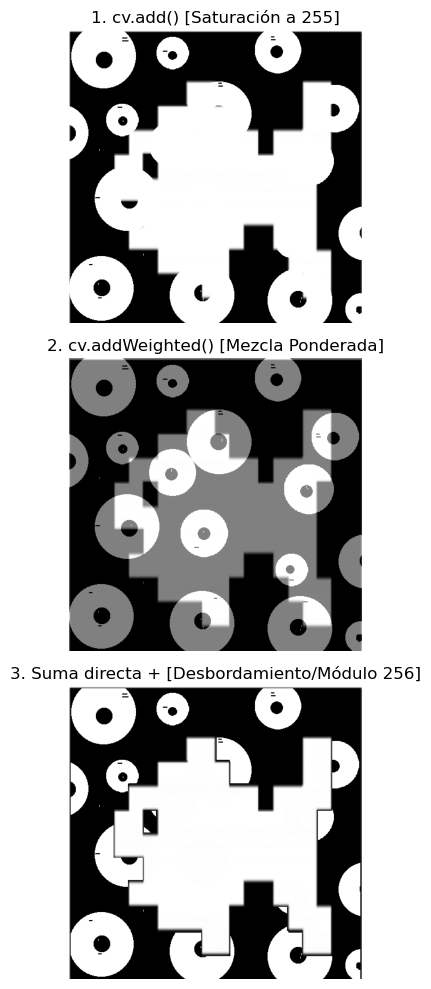

In [25]:
img1 = cv.imread('circulos_ruidos.png', 0)
img2 = cv.imread('pez.png', 0)

img2 = cv.resize(img2, (img1.shape[1], img1.shape[0]))

suma_add = cv.add(img1, img2)

suma_weighted = cv.addWeighted(img1, 0.5, img2, 0.5, 0)

suma_directa = img1 + img2


plt.figure(figsize=(10, 10))

plt.subplot(3, 1, 1)
plt.imshow(suma_add, cmap='gray')
plt.title('1. cv.add() (Saturación a 255)')
plt.axis('off')

plt.subplot(3, 1, 2)
plt.imshow(suma_weighted, cmap='gray')
plt.title('2. cv.addWeighted() (Mezcla Ponderada)')
plt.axis('off')

plt.subplot(3, 1, 3)
plt.imshow(suma_directa, cmap='gray')
plt.title('3. Suma directa + desbordamiento (Módulo 256)')
plt.axis('off')

plt.tight_layout()
plt.show()

La diferencia fundamental está en cómo gestionan los desbordamientos cuando la suma de dos píxeles supera el límite de 255:  

- Suma directa (img1 + img2): aplica aritmética con módulo 256. Si la suma supera 255. Esto genera sombras oscuras donde debería haber zonas muy claras.  
- cv.add(): Aplica saturación. si la suma supera 255, el valor se establece en 255 (blanco). Evita fallos de color pero tiende a blanquear la imagen.   
- cv.addWeighted(): aplica porcentajes antes de sumar. Al tomar por ejemplo el 50% de cada foto ($0.5 \times img1 + 0.5 \times img2$), garantiza matemáticamente que el resultado jamás supere 255, consiguiendo un efecto de transparencia limpia entre ambas imágenes.

### 📝 Ejercicio 6: 

- Aplica las funciones de openCV **converScaleAbs()** y **normalize()** sobre una imagen $I(x,y)$ definida por una matriz pequeña con valores que se salen del rango $[0,255]$. ¿Qué diferencia hay entre una y otra?
- Haz tú mismo/a las operaciones para llevar el rango inicial $[A,B]$ en el $[0,255]$: $\displaystyle\frac{I(x,y) – A}{B-A}*255$, pasando después el resultado a tipo de dato uint8.

In [31]:
I = np.array([[-100, -50, 0],
              [ 100, 200, 300],
              [ 400, 500, 600]], dtype=np.float32)

print("Matriz original I:\n", I)


res_convertScaleAbs = cv.convertScaleAbs(I)
print("\n1. Resultado cv.convertScaleAbs():\n", res_convertScaleAbs)



res_normalize = cv.normalize(I, None, alpha=0, beta=255, norm_type=cv.NORM_MINMAX, dtype=cv.CV_8U)
print("\n2. Resultado cv.normalize():\n", res_normalize)



Matriz original I:
 [[-100.  -50.    0.]
 [ 100.  200.  300.]
 [ 400.  500.  600.]]

1. Resultado cv.convertScaleAbs():
 [[100  50   0]
 [100 200 255]
 [255 255 255]]

2. Resultado cv.normalize():
 [[  0  18  36]
 [ 73 109 146]
 [182 219 255]]


- cv.convertScaleAbs(): aplica el valor absoluto a los números negativos y cualquier valor que sea mayor que 255 lo recorta fijándolo en 255. Pierdes el contraste y la proporción entre los valores altos porque todos los que superan 255 se vuelven exactamente 255. 

- cv.normalize(): busca el valor mínimo absoluto y el máximo de toda la matriz y comprime proporcionalmente todos los números para que encajen perfectamente en la escala de 0 a 255. Mantiene las distancias relativas y el contraste entre todos los píxeles sin recortar ningún dato.

In [27]:
A = I.min() 
B = I.max()

I_manual = ((I - A) / (B - A)) * 255
I_manual_uint8 = I_manual.astype(np.uint8)

print("\n3. Resultado Fórmula Manual (uint8):\n", I_manual_uint8)


3. Resultado Fórmula Manual (uint8):
 [[  0  18  36]
 [ 72 109 145]
 [182 218 255]]


### 📝 Ejercicio 7: 

- Carga varias imágenes en escala de grises: claras, oscuras, con mucho contraste, con poco contraste.
- Representa el **histograma** de cada una de ellas.
- Observa la información que puedes obtener de las imágenes a partir de dichos histogramas.

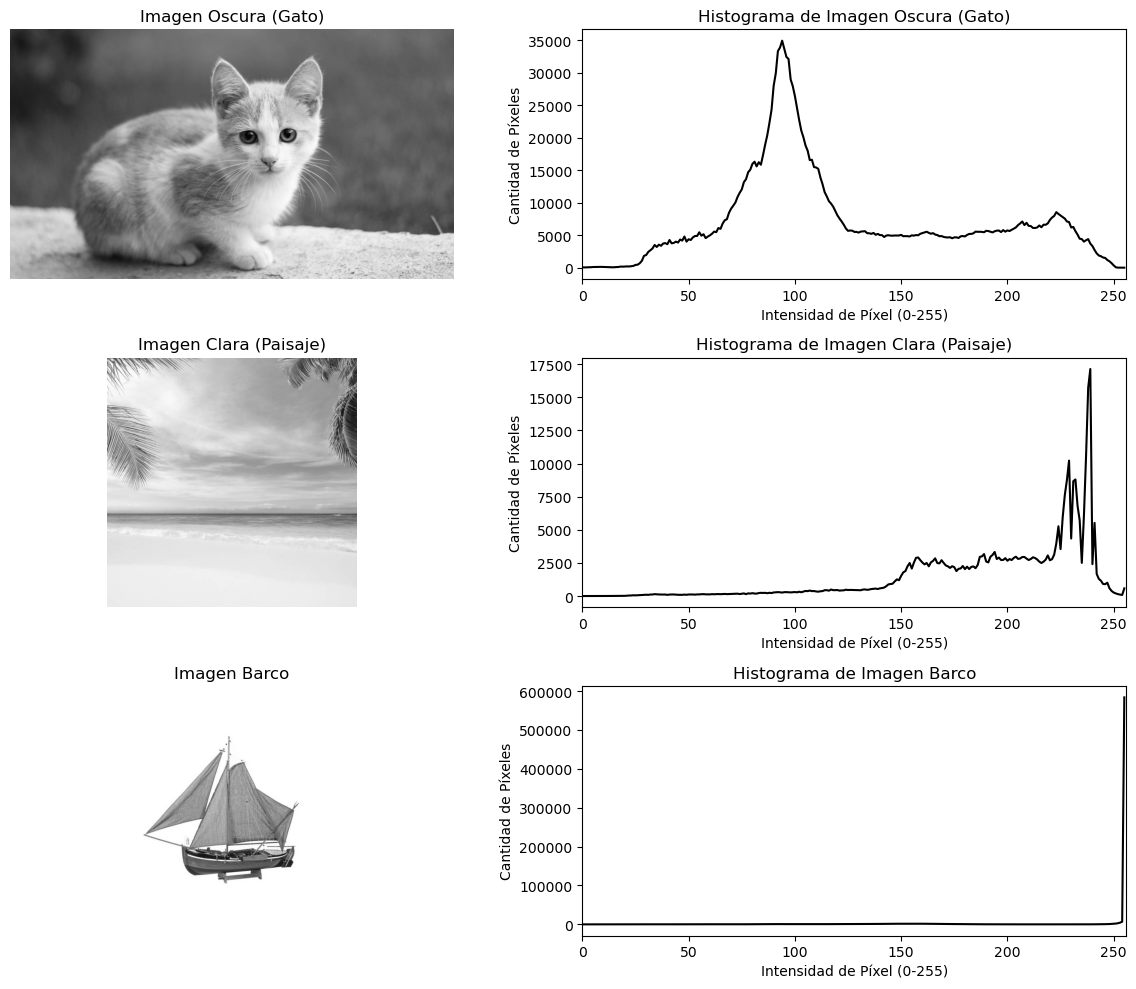

In [33]:
img_oscura = cv.imread('gato.jpg', cv.IMREAD_GRAYSCALE)
img_clara  = cv.imread('paisaje.jpg', cv.IMREAD_GRAYSCALE)
img_barco  = cv.imread('barco.jpg', cv.IMREAD_GRAYSCALE)

# Lista de imágenes y sus títulos
imagenes = [img_oscura, img_clara, img_barco]
titulos = ['Imagen Oscura (Gato)', 'Imagen Clara (Paisaje)', 'Imagen Barco']

#  Representar las imágenes junto a su histograma
plt.figure(figsize=(12, 10))

for i in range(3):
    # Calcular el histograma (256 bins, rango de 0 a 255)
    # SINTAXIS: cv.calcHist(images, channels, mask, histSize, ranges)
    
    # 1. [imagenes[i]] -> Imagen de entrada (siempre envuelta en lista [])
    # 2. [0]           -> Canal a analizar (0 para escala de grises / primer canal)
    # 3. None          -> Sin máscara (calcula el histograma de toda la imagen)
    # 4. [256]         -> Número de bins/barras (1 barra por cada nivel de 0 a 255)
    # 5. [0, 256]      -> Rango de intensidades a medir (de 0 a 255; el 256 es excluyente)


    hist = cv.calcHist([imagenes[i]], [0], None, [256], [0, 256])
    
    # Mostrar la imagen
    plt.subplot(3, 2, 2*i + 1)
    plt.imshow(imagenes[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titulos[i])
    plt.axis('off')
    
    # Mostrar su histograma
    plt.subplot(3, 2, 2*i + 2)
    plt.plot(hist, color='black')
    plt.title(f'Histograma de {titulos[i]}')
    plt.xlim([0, 256])
    plt.xlabel('Intensidad de Píxel (0-255)')
    plt.ylabel('Cantidad de Píxeles')

plt.tight_layout()
plt.show()

- Imagen del Gato: la gráfica muestra una concentración alta de píxeles en el rango de 70 a 120. La mayoría de la escena está compuesta por sombras y tonos grises oscuros (el pelaje y el fondo), con muy poca presencia de blancos puros.

- Imagen del Paisaje: acumula píxeles entre 200 y 245. Es una imagen muy iluminada donde predominan los tonos cerca del blanco (el cielo brillante y la arena).

- Imagen del Barco: muestra una línea prácticamente plana en casi todo el eje y una columna gigante justamente en el valor 255. El fondo de la imagen es blanco puro absoluto (255). Al ocupar casi todo el tapiz, eclipsa la pequeña cantidad de píxeles oscuros pertenecientes al barco.

### 📝 Ejercicio 8: 

- Carga una imagen en escala de grises y aplícale transformaciones lineales $T(r) = a r + b$ variando los valores de los parámetros $a$ y $b$.
- Analiza los resultados obtenidos.

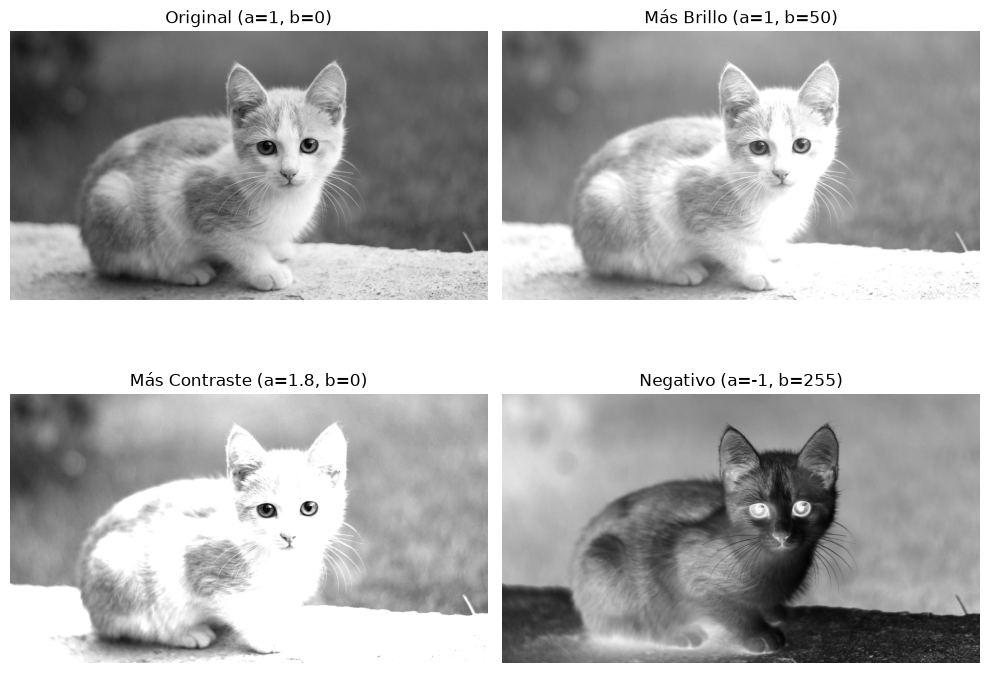

In [6]:
# a (alpha) -> CONTRASTE: Multiplica la intensidad del píxel.
#              a > 1 aumenta contraste, a < 1 lo reduce.
# b (beta)  -> BRILLO: Suma o resta un valor constante a cada píxel.
#              b > 0 aclara, b < 0 oscurece.
img = cv.imread('gato.jpg', cv.IMREAD_GRAYSCALE)

# Caso A: Aumentar brillo (a=1, b=50)
img_brillo = cv.convertScaleAbs(img, alpha=1.0, beta=50)

# Caso B: Aumentar contraste (a=1.8, b=0)
img_contraste = cv.convertScaleAbs(img, alpha=1.8, beta=0)

# Caso C: Invertir la imagen / Negativo (a=-1, b=255)
img_negativo = cv.convertScaleAbs(img, alpha=-1.0, beta=255)

# 3. Mostrar los resultados
plt.figure(figsize=(10, 8))

plt.subplot(2, 2, 1)
plt.imshow(img, cmap='gray', vmin=0, vmax=255)
plt.title('Original (a=1, b=0)')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(img_brillo, cmap='gray', vmin=0, vmax=255)
plt.title('Más Brillo (a=1, b=50)')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(img_contraste, cmap='gray', vmin=0, vmax=255)
plt.title('Más Contraste (a=1.8, b=0)')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(img_negativo, cmap='gray', vmin=0, vmax=255)
plt.title('Negativo (a=-1, b=255)')
plt.axis('off')

plt.tight_layout()
plt.show()

Al aplicar la transformación lineal sobre la imagen del gato, se observan los siguientes comportamientos:

- Original: representa la imagen base sin modificaciones, sirviendo como punto de comparación.

- Aumento de brillo: al sumar un valor constante (b = 50), todos los píxeles se desplazan hacia el blanco. Toda la imagen se percibe globalmente más clara y lavada.

- Aumento de Contraste: al multiplicar por (a = 1.8), las diferencias entre tonos se amplifican. Las zonas claras del lomo del gato se saturan a blanco puro, mientras que las sombras se marcan más, ganando muchísima fuerza pero perdiendo detalle en las zonas quemadas.

- Inversión: se invierte la escala de grises. El pelaje claro del gato pasa a verse completamente negro y el fondo oscuro pasa a ser claro, produciendo el efecto de un negativo fotográfico.

### 📝 Ejercicio 9: 

- Carga una imagen en escala de grises que tenga zonas con bajo nivel de intensidad.
- Aplica la transformación log $T(r) = C log(1 + r)$ a dicha imagen y analiza el efecto que produce en dichas zonas.

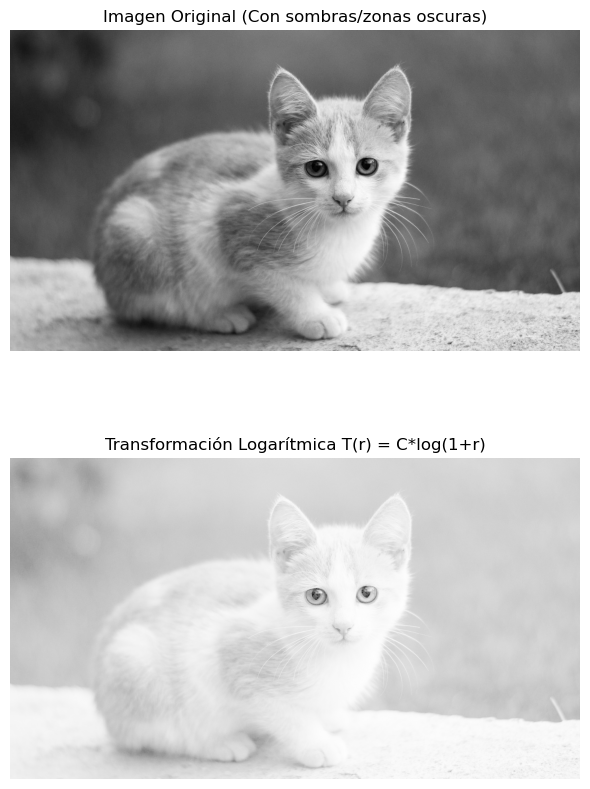

In [36]:
# TRANSFORMACIÓN LOGARÍTMICA: T(r) = C * log(1 + r)
#
# r     -> Intensidad del píxel original.
# 1 + r -> Evita log(0), garantizando que log(1) = 0.
# C     -> Constante de escala: C = 255 / log(1 + max_val). Mantiene el resultado en [0, 255].
#
# EFECTO: Expande/aclara las zonas muy OSCURAS y comprime las zonas claras.
# USO: Revelar detalles ocultos en sombras o visualizar espectros de Fourier.

img = cv.imread('gato.jpg', cv.IMREAD_GRAYSCALE)
img_float = img.astype(np.float32)


c = 255 / np.log(1 + np.max(img_float))
img_log = c * np.log(1 + img_float)

img_log = np.array(img_log, dtype=np.uint8)

plt.figure(figsize=(6, 10))

plt.subplot(2, 1, 1)
plt.imshow(img, cmap='gray', vmin=0, vmax=255)
plt.title('Imagen Original (Con sombras/zonas oscuras)')
plt.axis('off')

plt.subplot(2, 1, 2)
plt.imshow(img_log, cmap='gray', vmin=0, vmax=255)
plt.title('Transformación Logarítmica T(r) = C*log(1+r)')
plt.axis('off')

plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show()

La función logarítmica produce una expansión de las intensidades bajas (zonas oscuras) y una compresión de las intensidades altas (zonas claras).

- Efecto en zonas oscuras (baja intensidad):
  * La curva del logaritmo crece muy rápido en los valores cercanos a cero.
  * Esto provoca que las diferencias entre tonos oscuros que antes eran imperceptibles se amplíen, revelando detalles ocultos en las sombras sin quemar la imagen.

- Efecto en zonas claras (alta intensidad):
  * En los valores altos de gris, la pendiente del logaritmo se vuelve casi plana, por lo que comprime esos rangos y reduce el contraste en los tonos más claros.



### 📝 Ejercicio 10: 

-  Carga dos imágenes en escala de grises con poco contraste, una clara y otra oscura.   
- Realiza la transformación gamma $T(r) = C r^\gamma$ a la imagen clara para distintos valores de $\gamma > 1$ y analiza los resultados.
- Realiza la transformación gamma $T(r) = C r^\gamma$ a la imagen oscura para distintos valores de $\gamma < 1$ y analiza los resultados.

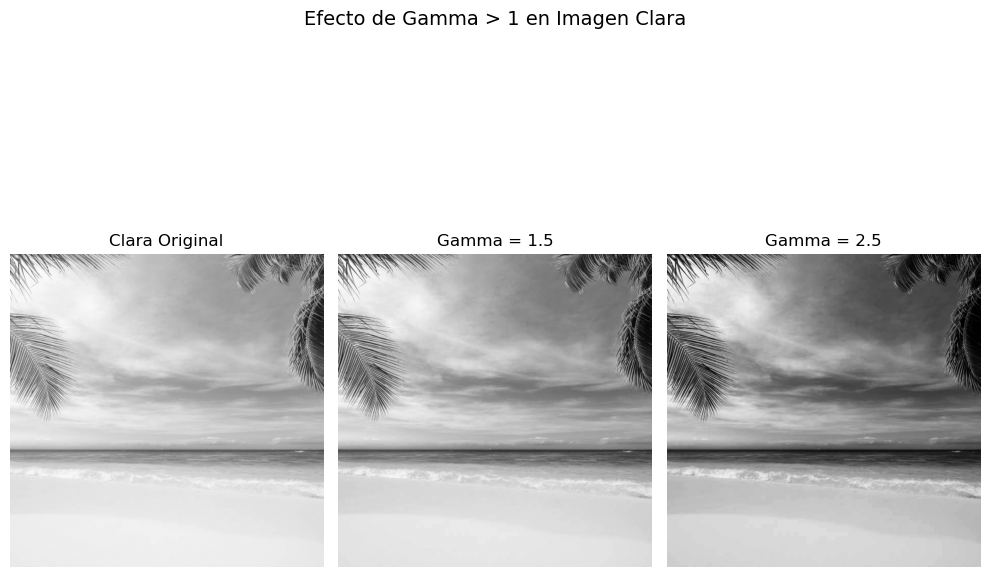

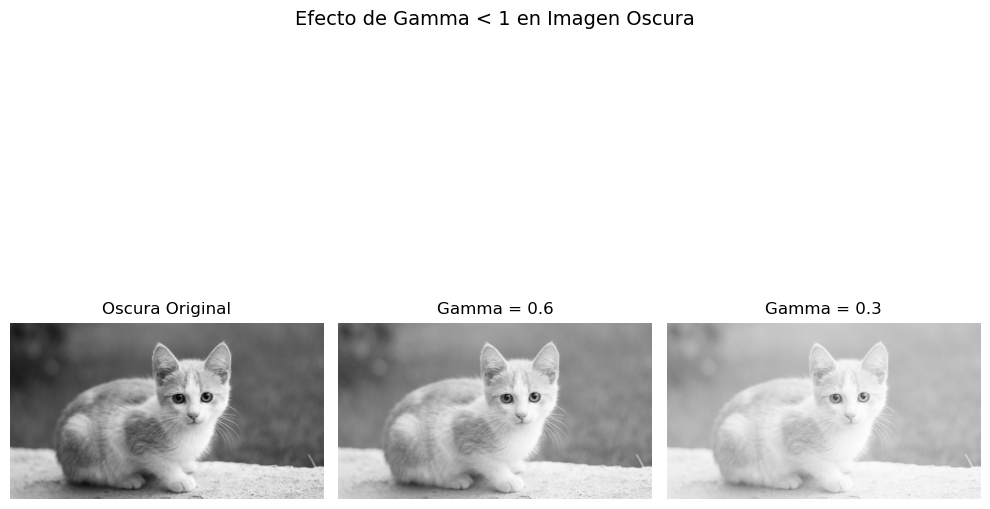

In [37]:
# r     -> Intensidad del píxel normalizado [0.0, 1.0].
# gamma -> Exponente de corrección:
#          gamma < 1 : Aclara la imagen (resalta detalles en zonas OSCURAS).
#          gamma > 1 : Oscurece la imagen (comprime sombras, resalta BRILLOS).
#          gamma = 1 : Mantiene la imagen sin cambios.
#
# USO: Corrección de contraste flexible y calibración de monitores/cámaras.

# Función auxiliar para aplicar la transformación Gamma
def transformacion_gamma(img, gamma):
    # 1. Normalizar al rango [0, 1]
    img_norm = img / 255.0
    # 2. Aplicar la potencia gamma: T(r) = r^gamma
    gamma_corr = np.power(img_norm, gamma)
    # 3. Volver a escalar al rango [0, 255] y convertir a uint8
    return np.uint8(gamma_corr * 255)

# 1. Cargar las dos imágenes: una clara (paisaje) y una oscura (gato)
img_clara  = cv.imread('paisaje.jpg', cv.IMREAD_GRAYSCALE)
img_oscura = cv.imread('gato.jpg', cv.IMREAD_GRAYSCALE)

# 2. Aplicar gamma > 1 a la imagen CLARA (para oscurecerla y ganar contraste)
clara_g1_5 = transformacion_gamma(img_clara, 1.5)
clara_g2_5 = transformacion_gamma(img_clara, 2.5)

# 3. Aplicar gamma < 1 a la imagen OSCURA (para aclararla y recuperar detalle)
oscura_g0_6 = transformacion_gamma(img_oscura, 0.6)
oscura_g0_3 = transformacion_gamma(img_oscura, 0.3)

# 4. Mostrar resultados para la Imagen Clara (Gamma > 1)
plt.figure(figsize=(10, 8))

plt.subplot(1, 3, 1)
plt.imshow(img_clara, cmap='gray', vmin=0, vmax=255)
plt.title('Clara Original')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(clara_g1_5, cmap='gray', vmin=0, vmax=255)
plt.title('Gamma = 1.5')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(clara_g2_5, cmap='gray', vmin=0, vmax=255)
plt.title('Gamma = 2.5')
plt.axis('off')

plt.suptitle('Efecto de Gamma > 1 en Imagen Clara', fontsize=14)
plt.tight_layout()
plt.show()

# 5. Mostrar resultados para la Imagen Oscura (Gamma < 1)
plt.figure(figsize=(10, 8))

plt.subplot(1, 3, 1)
plt.imshow(img_oscura, cmap='gray', vmin=0, vmax=255)
plt.title('Oscura Original')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(oscura_g0_6, cmap='gray', vmin=0, vmax=255)
plt.title('Gamma = 0.6')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(oscura_g0_3, cmap='gray', vmin=0, vmax=255)
plt.title('Gamma = 0.3')
plt.axis('off')

plt.suptitle('Efecto de Gamma < 1 en Imagen Oscura', fontsize=14)
plt.tight_layout()
plt.show()

### Análisis de la Transformación Gamma 

La transformación Ley de la Potencia (Gamma) permite ajustar la curva de contraste de forma no lineal según el valor del parámetro \(\gamma\):

1. **Caso $\gamma > 1$ (Aplicado a la imagen clara):**
   * **Efecto:** Comprime los tonos oscuros y medios hacia valores aún más oscuros (curva convexa hacia abajo).
   * **Resultado:** **Oscurece la imagen globalmente**. Permite corregir imágenes lavadas o sobreexpuestas, devolviéndoles el contraste y recuperando textura en las zonas muy claras que parecían blanquecinas.
   * A mayor valor de \(\gamma\) (ej. \(\gamma = 2.5\)), mayor es el nivel de oscurecimiento.

2. **Caso $\gamma <1$ (Aplicado a la imagen oscura):**
   * **Efecto:** Expande los tonos oscuros y los desplaza hacia niveles más claros de gris (curva cóncava hacia arriba, similar a la función logarítmica).
   * **Resultado:** **Aclara la imagen globalmente**. Es ideal para recuperar información en escenas subexpuestas o con sombras marcadas, rescatando detalles ocultos en los tonos oscuros sin quemar en exceso las zonas medias.
   * A menor valor de \(\gamma\) (ej. \(\gamma = 0.3\)), la imagen se vuelve progresivamente más clara.

### 📝 Ejercicio 11: 

- Carga una imagen en escala de grises con poco contraste.
- Realiza las transformaciones **expansión y ecualización** al histograma de dicha imagen.
- Analiza el efecto que produce y visualiza los histogramas de las imágenes resultantes.

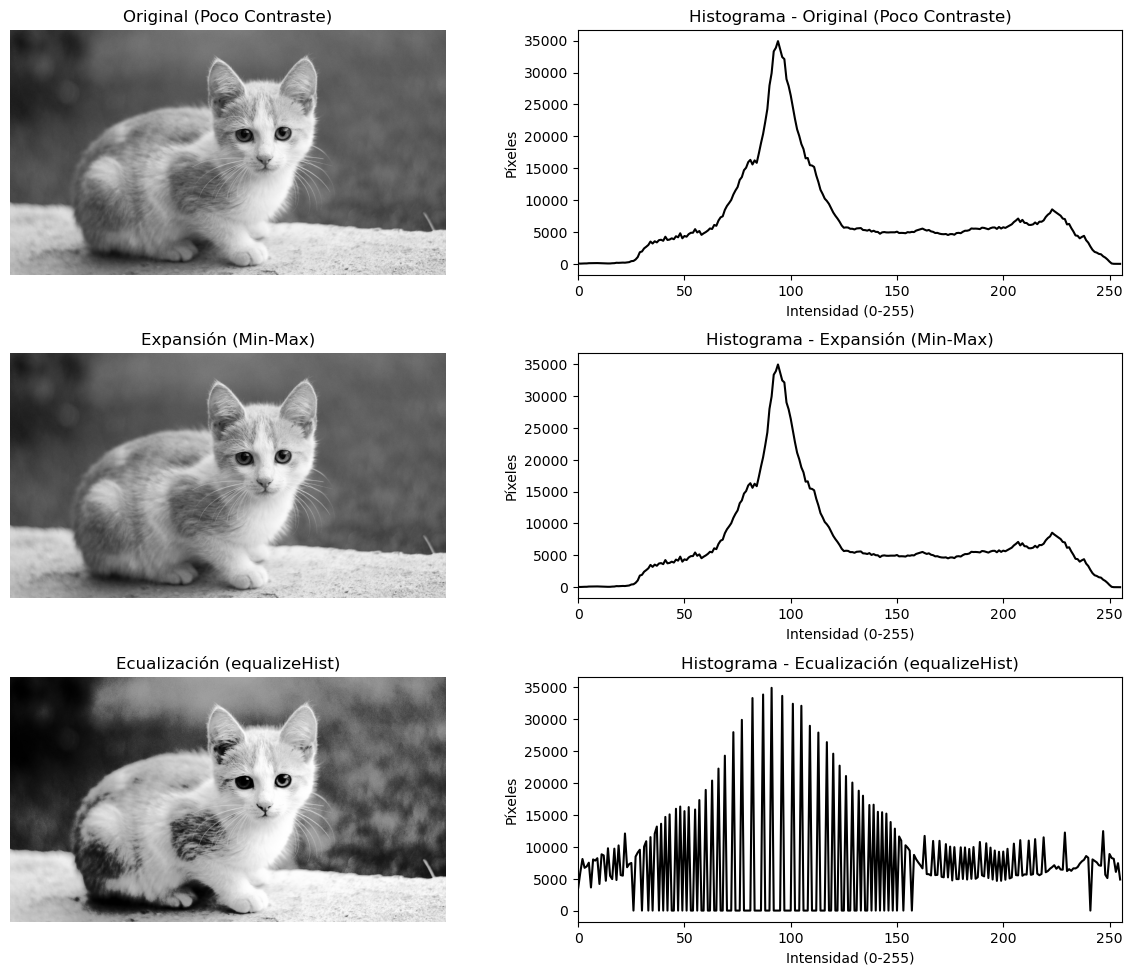

In [38]:
img = cv.imread('gato.jpg', cv.IMREAD_GRAYSCALE)

# 2. Expansión del histograma (Normalización lineal min-max al rango [0, 255])
img_exp = cv.normalize(img, None, alpha=0, beta=255, norm_type=cv.NORM_MINMAX, dtype=cv.CV_8U)

# 3. Ecualización del histograma (Distribución uniforme acumulada)
img_ecu = cv.equalizeHist(img)

# Lista de imágenes, títulos y sus histogramas
imgs = [img, img_exp, img_ecu]
titulos = ['Original (Poco Contraste)', 'Expansión (Min-Max)', 'Ecualización (equalizeHist)']

# 4. Visualizar imágenes e histogramas juntos
plt.figure(figsize=(12, 10))

for i in range(3):
    # Imagen
    plt.subplot(3, 2, 2*i + 1)
    plt.imshow(imgs[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titulos[i])
    plt.axis('off')
    
    # Histograma
    plt.subplot(3, 2, 2*i + 2)
    hist = cv.calcHist([imgs[i]], [0], None, [256], [0, 256])
    plt.plot(hist, color='black')
    plt.xlim([0, 256])
    plt.title(f'Histograma - {titulos[i]}')
    plt.xlabel('Intensidad (0-255)')
    plt.ylabel('Píxeles')

plt.tight_layout()
plt.subplots_adjust(top=0.95)
plt.show()

### Análisis de Expansión vs. Ecualización de Histograma

Ambas técnicas buscan mejorar el contraste de una imagen con un rango dinámico pobre, pero operan de forma matemáticamente distinta:

1. **Expansión del Histograma (Stretching / Min-Max):**
   * **Mecanismo:** Toma el valor mínimo (\(A\)) y máximo (\(B\)) de la imagen original y realiza una transformación lineal para estirarlos a $0$ y $255$.
   * **Efecto en la imagen:** Aumenta el contraste de forma respetuosa sin alterar la forma o proporciones de la distribución original.
   * **Efecto en el histograma:** La forma básica de la curva no cambia; simplemente se "estira" a lo largo de todo el eje horizontal de 0 a 255.

2. **Ecualización del Histograma (`cv.equalizeHist`):**
   * **Mecanismo:** Utiliza la Función de Distribución Acumulada (CDF) para aplanar la gráfica y aplanar la cantidad de píxeles en todos los niveles de gris.
   * **Efecto en la imagen:** Maximiza el contraste global. Es ideal para revelar detalles muy ocultos en zonas oscuras o claras, aunque a veces puede sobre-contrastar la escena o amplificar el ruido de fondo.
   * **Efecto en el histograma:** Redistribuye los píxeles intentando que la curva sea lo más uniforme y plana posible en todo el rango \([0, 255]\).